In [1]:
from google.colab import files

uploaded = files.upload()

Saving SAI_Dissertation.zip to SAI_Dissertation.zip


In [60]:
import zipfile
import os

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/brca1_dataset')

print("Dataset extracted successfully.")

Dataset extracted successfully.


In [61]:
for root, dirs, files in os.walk('/content/brca1_dataset'):
    print(root)
    for file in files:
        print("   ", file)

/content/brca1_dataset
/content/brca1_dataset/Different Species gene
/content/brca1_dataset/Different Species gene/dog
    data_report.jsonl
    gene.fna
    protein.faa
    dataset_catalog.json
    rna.fna
/content/brca1_dataset/Different Species gene/domestic cat
    data_report.jsonl
    gene.fna
    protein.faa
    dataset_catalog.json
    rna.fna
/content/brca1_dataset/Different Species gene/Chicken
    data_report.jsonl
    gene.fna
    protein.faa
    dataset_catalog.json
    rna.fna
/content/brca1_dataset/Different Species gene/Chimpanzee
    data_report.jsonl
    gene.fna
    protein.faa
    dataset_catalog.json
    rna.fna
/content/brca1_dataset/Different Species gene/Human
    data_report.jsonl
    gene.fna
    protein.faa
    dataset_catalog.json
    rna.fna
/content/brca1_dataset/Different Species gene/House mouse
    data_report.jsonl
    gene.fna
    protein.faa
    dataset_catalog.json
    rna.fna


In [4]:
!pip install biopython -q

In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from Bio import SeqIO

In [6]:
import glob

fasta_files = glob.glob(
    "/content/brca1_dataset/**/*.fna",
    recursive=True
) + glob.glob(
    "/content/brca1_dataset/**/*.faa",
    recursive=True
)

print("Number of FASTA files:", len(fasta_files))

for file in fasta_files:
    print(file)

Number of FASTA files: 18
/content/brca1_dataset/Different Species gene/dog/gene.fna
/content/brca1_dataset/Different Species gene/dog/rna.fna
/content/brca1_dataset/Different Species gene/domestic cat/gene.fna
/content/brca1_dataset/Different Species gene/domestic cat/rna.fna
/content/brca1_dataset/Different Species gene/Chicken/gene.fna
/content/brca1_dataset/Different Species gene/Chicken/rna.fna
/content/brca1_dataset/Different Species gene/Chimpanzee/gene.fna
/content/brca1_dataset/Different Species gene/Chimpanzee/rna.fna
/content/brca1_dataset/Different Species gene/Human/gene.fna
/content/brca1_dataset/Different Species gene/Human/rna.fna
/content/brca1_dataset/Different Species gene/House mouse/gene.fna
/content/brca1_dataset/Different Species gene/House mouse/rna.fna
/content/brca1_dataset/Different Species gene/dog/protein.faa
/content/brca1_dataset/Different Species gene/domestic cat/protein.faa
/content/brca1_dataset/Different Species gene/Chicken/protein.faa
/content/brca

In [7]:
sequence_data = []

for file in fasta_files:

    if "gene.fna" in file:
        sequence_type = "DNA"
    elif "rna.fna" in file:
        sequence_type = "RNA"
    elif "protein.faa" in file:
        sequence_type = "Protein"

    species = os.path.basename(os.path.dirname(file))

    for record in SeqIO.parse(file, "fasta"):
        sequence_data.append({
            "file": os.path.basename(file),
            "species": species,
            "sequence_type": sequence_type,
            "id": record.id,
            "description": record.description,
            "sequence": str(record.seq)
        })

df = pd.DataFrame(sequence_data)

print("Total sequences:", len(df))

Total sequences: 914


In [8]:
df.head()

,file,species,sequence_type,id,description,sequence
0,gene.fna,dog,DNA,NC_051813.1:20677057-20743989,NC_051813.1:20677057-20743989 BRCA1 [organism=...,ACTGATTGGTCGAGCCTGCGTGGCAGGGGTGGGGCAAGAGCTGCCA...
1,gene.fna,dog,DNA,NC_049269.1:19464421-19527988,NC_049269.1:19464421-19527988 BRCA1 [organism=...,ATGGATTTATCTGCGGATCGTGTTGAAGAAGTACAAAATGTTCTTA...
2,gene.fna,dog,DNA,NC_049750.1:19730981-19794752,NC_049750.1:19730981-19794752 BRCA1 [organism=...,ATGGATTTATCTGCGGATCGTGTTGAAGAAGTACAAAATGTTCTTA...
3,gene.fna,dog,DNA,NC_049230.1:19833116-19896786,NC_049230.1:19833116-19896786 BRCA1 [organism=...,ATGGATTTATCTGCGGATCGTGTTGAAGAAGTACAAAATGTTCTTA...
4,gene.fna,dog,DNA,NC_006591.4:19422566-19486083,NC_006591.4:19422566-19486083 BRCA1 [organism=...,ATGGATTTATCTGCGGATCGTGTTGAAGAAGTACAAAATGTTCTTA...


In [9]:
df.tail(10)

,file,species,sequence_type,id,description,sequence
904,protein.faa,Human,Protein,NP_009225.1,NP_009225.1 BRCA1 [organism=Homo sapiens] [Gen...,MDLSALRVEEVQNVINAMQKILECPICLELIKEPVSTKCDHIFCKF...
905,protein.faa,Human,Protein,NP_009228.2,NP_009228.2 BRCA1 [organism=Homo sapiens] [Gen...,MLKLLNQKKGPSQCPLCKNDITKRSLQESTRFSQLVEELLKIICAF...
906,protein.faa,Human,Protein,NP_009229.2,NP_009229.2 BRCA1 [organism=Homo sapiens] [Gen...,MDLSALRVEEVQNVINAMQKILECPICLELIKEPVSTKCDHIFCKF...
907,protein.faa,Human,Protein,NP_009230.2,NP_009230.2 BRCA1 [organism=Homo sapiens] [Gen...,MDLSALRVEEVQNVINAMQKILECPICLELIKEPVSTKCDHIFCKF...
908,protein.faa,Human,Protein,NP_009231.2,NP_009231.2 BRCA1 [organism=Homo sapiens] [Gen...,MDLSALRVEEVQNVINAMQKILECPICLELIKEPVSTKCDHIFCKF...
909,protein.faa,House mouse,Protein,NP_033894.3,NP_033894.3 Brca1 [organism=Mus musculus] [Gen...,MDLSAVQIQEVQNVLHAMQKILECPICLELIKEPVSTKCDHIFCKF...
910,protein.faa,House mouse,Protein,XP_006532127.1,XP_006532127.1 Brca1 [organism=Mus musculus] [...,MDLSAVQIQEVQNVLHAMQKILECPICLELIKEPVSTKCDHIFCKF...
911,protein.faa,House mouse,Protein,XP_006532131.1,XP_006532131.1 Brca1 [organism=Mus musculus] [...,MDLSAVQIQEVQNVLHAMQKILECPICLELIKEPVSTKCDHIFCKF...
912,protein.faa,House mouse,Protein,XP_030101355.1,XP_030101355.1 Brca1 [organism=Mus musculus] [...,MDLSAVQIQEVQNVLHAMQKILECPICLELIKEPVSTKCDHIFCKF...
913,protein.faa,House mouse,Protein,XP_036012146.1,XP_036012146.1 Brca1 [organism=Mus musculus] [...,MLKLLNQKKGPSQCPLCKNEITKRSLQGSTRFSQLAEELLRIMAAF...


In [10]:
df["sequence_type"].value_counts()

,count
sequence_type,
RNA,452
Protein,450
DNA,12


In [11]:
df["species"].value_counts()

,count
species,
Human,738
Chimpanzee,103
dog,30
domestic cat,19
Chicken,12
House mouse,12


In [12]:
dna_df = df[df["sequence_type"] == "DNA"].copy()
rna_df = df[df["sequence_type"] == "RNA"].copy()
protein_df = df[df["sequence_type"] == "Protein"].copy()

print("DNA:", len(dna_df))
print("RNA:", len(rna_df))
print("Protein:", len(protein_df))

DNA: 12
RNA: 452
Protein: 450


In [13]:
print("Missing sequences:", df["sequence"].isna().sum())
print("Empty sequences:", (df["sequence"] == "").sum())

Missing sequences: 0
Empty sequences: 0


In [14]:
df["length"] = df["sequence"].str.len()

df[["species", "sequence_type", "length"]].head()

,species,sequence_type,length
0,dog,DNA,66933
1,dog,DNA,63568
2,dog,DNA,63772
3,dog,DNA,63671
4,dog,DNA,63518


In [15]:
df.groupby("sequence_type")["length"].describe()

,count,mean,std,min,25%,50%,75%,max
sequence_type,,,,,,,,
DNA,12.0,68239.916667,32322.738122,21170.0,62113.25,63619.5,70400.25,126228.0
Protein,450.0,1424.140000,527.935206,451.0,758.00,1792.0,1821.00,1934.0
RNA,452.0,5878.331858,1624.051105,2825.0,3776.00,6956.0,7082.50,8243.0


In [16]:
print("Total sequences:", len(df))
print("Unique sequences:", df["sequence"].nunique())
print("Duplicate records:", df.duplicated("sequence").sum())

Total sequences: 914
Unique sequences: 661
Duplicate records: 253


In [17]:
dna_unique = dna_df.drop_duplicates(
    subset="sequence"
).copy()

print("Original DNA:", len(dna_df))
print("Unique DNA:", len(dna_unique))

Original DNA: 12
Unique DNA: 12


In [18]:
rna_unique = rna_df.drop_duplicates(
    subset="sequence"
).copy()

print("Original RNA:", len(rna_df))
print("Unique RNA:", len(rna_unique))

Original RNA: 452
Unique RNA: 452


In [62]:
protein_unique = protein_df.drop_duplicates(
    subset=["species", "sequence"]
).copy()

print("Original protein:", len(protein_df))
print("Unique protein:", len(protein_unique))

Original protein: 450
Unique protein: 197


In [63]:
duplicate_summary = pd.DataFrame({
    "Sequence Type": ["DNA", "RNA", "Protein"],
    "Original": [
        len(dna_df),
        len(rna_df),
        len(protein_df)
    ],
    "Unique": [
        len(dna_unique),
        len(rna_unique),
        len(protein_unique)
    ]
})

duplicate_summary["Duplicates"] = (
    duplicate_summary["Original"] -
    duplicate_summary["Unique"]
)

duplicate_summary

,Sequence Type,Original,Unique,Duplicates
0,DNA,12,12,0
1,RNA,452,452,0
2,Protein,450,197,253


In [64]:
species_type_table = pd.crosstab(
    df["species"],
    df["sequence_type"]
)

species_type_table

sequence_type,DNA,Protein,RNA
species,,,
Chicken,2,5,5
Chimpanzee,1,51,51
House mouse,1,5,6
Human,2,368,368
dog,5,12,13
domestic cat,1,9,9


In [65]:
protein_unique.groupby(
    "species"
)["sequence"].nunique()

,sequence
species,
Chicken,5
Chimpanzee,28
House mouse,4
Human,146
dog,8
domestic cat,6


In [66]:
valid_dna = set("ACGTN")

invalid_dna = dna_unique[
    ~dna_unique["sequence"].apply(
        lambda x: set(x.upper()).issubset(valid_dna)
    )
]

print("Invalid DNA sequences:", len(invalid_dna))

Invalid DNA sequences: 0


In [67]:
# Check which characters are present in the RNA sequences

rna_characters = set(
    "".join(rna_unique["sequence"]).upper()
)

print("RNA characters found:")
print(sorted(rna_characters))

RNA characters found:
['A', 'C', 'G', 'T']


In [68]:
# Count each character in the RNA sequences

from collections import Counter

rna_counts = Counter(
    "".join(rna_unique["sequence"]).upper()
)

print(rna_counts)

Counter({'A': 862975, 'T': 658198, 'G': 606606, 'C': 529227})


In [69]:
valid_rna = set("ACGTN")

invalid_rna = rna_unique[
    ~rna_unique["sequence"].apply(
        lambda x: set(x.upper()).issubset(valid_rna)
    )
]

print("Invalid RNA sequences:", len(invalid_rna))

Invalid RNA sequences: 0


In [70]:
valid_protein = set("ACDEFGHIKLMNPQRSTVWYBXZJUO")

invalid_protein = protein_unique[
    ~protein_unique["sequence"].apply(
        lambda x: set(x.upper()).issubset(valid_protein)
    )
]

print("Invalid protein sequences:", len(invalid_protein))

Invalid protein sequences: 0


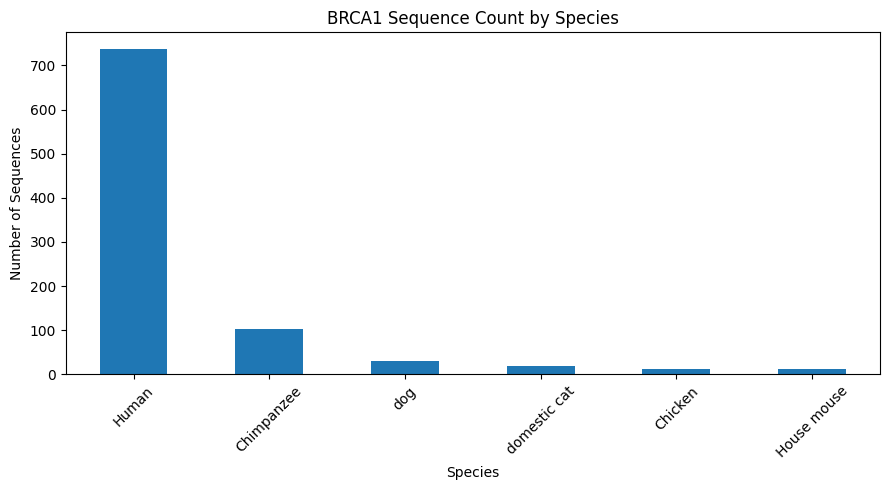

In [71]:
plt.figure(figsize=(9, 5))

df["species"].value_counts().plot(kind="bar")

plt.title("BRCA1 Sequence Count by Species")
plt.xlabel("Species")
plt.ylabel("Number of Sequences")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

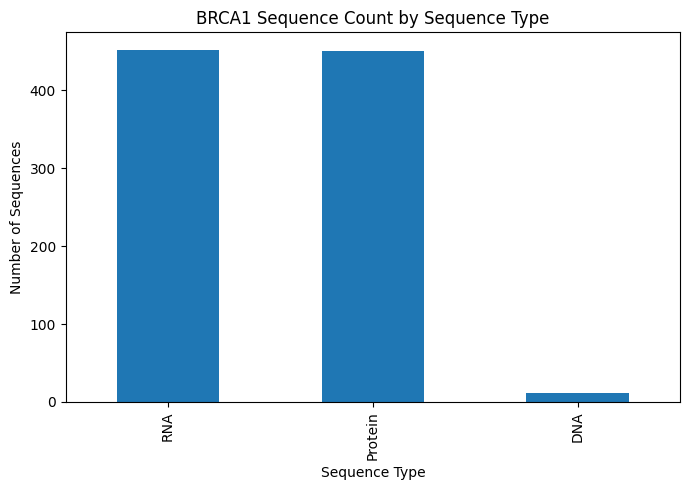

In [72]:
plt.figure(figsize=(7, 5))

df["sequence_type"].value_counts().plot(kind="bar")

plt.title("BRCA1 Sequence Count by Sequence Type")
plt.xlabel("Sequence Type")
plt.ylabel("Number of Sequences")
plt.tight_layout()
plt.show()

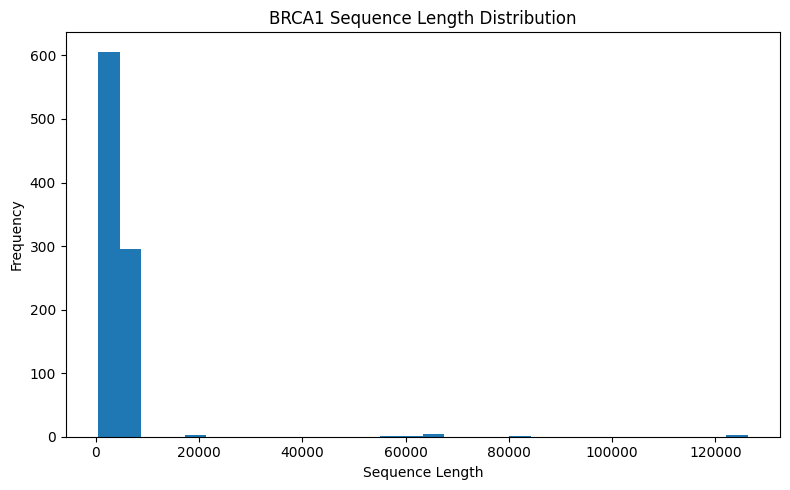

In [73]:
plt.figure(figsize=(8, 5))

df["length"].plot(
    kind="hist",
    bins=30
)

plt.title("BRCA1 Sequence Length Distribution")
plt.xlabel("Sequence Length")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

In [74]:
protein_unique.columns

Index(['file', 'species', 'sequence_type', 'id', 'description', 'sequence'], dtype='object')

In [75]:
protein_unique["length"] = protein_unique["sequence"].str.len()

protein_unique.groupby(
    "species"
)["length"].agg(
    ["count", "min", "max", "mean", "median"]
)

,count,min,max,mean,median
species,,,,,
Chicken,5,1749,1750,1749.400000,1749.0
Chimpanzee,28,718,1863,1412.214286,1820.0
House mouse,4,707,1812,1512.750000,1766.0
Human,146,451,1885,1328.691781,1750.0
dog,8,811,1934,1622.875000,1878.0
domestic cat,6,765,1873,1503.166667,1871.5


In [76]:
protein_unique[["species", "length", "sequence"]].head()

,species,length,sequence
464,dog,1878,MDLSADRVEEVQNVLNAMQKILECPICLELIKEPVSTKCDHIFCKF...
465,dog,1934,MVREQGPFLRLSQALSCAHIRASGSDSSHLCDVISPEWKPKEKMDL...
466,dog,1921,MVREQGPFLRLSQALSCAHIRASGSDSSHLCDVISPEWKPKEKMDL...
467,dog,1891,MDLSADRVEEVQNVLNAMQKILECPICHLPMLETQNANTRLELIKE...
470,dog,1878,MDLSADRVEEVQNVLNAMQKILECPICLELIKEPVSTKCDHIFCKF...


In [77]:
def get_kmers(sequence, k=3):
    return [
        sequence[i:i+k]
        for i in range(len(sequence) - k + 1)
    ]

In [78]:
print(get_kmers("MKTABC", 3))

['MKT', 'KTA', 'TAB', 'ABC']


In [79]:
from collections import Counter

def kmer_frequency(sequence, k=3):
    kmers = get_kmers(sequence, k)
    counts = Counter(kmers)
    total = len(kmers)

    return {
        kmer: count / total
        for kmer, count in counts.items()
    }

In [80]:
print(kmer_frequency("MKTABC", 3))

{'MKT': 0.25, 'KTA': 0.25, 'TAB': 0.25, 'ABC': 0.25}


In [81]:
kmer_features = protein_unique["sequence"].apply(
    lambda x: kmer_frequency(x, 3)
)

print("Number of sequences:", len(kmer_features))

Number of sequences: 197


In [82]:
from sklearn.feature_extraction import DictVectorizer

vectorizer = DictVectorizer(
    sparse=False
)

X = vectorizer.fit_transform(
    kmer_features
)

print("Feature matrix:", X.shape)

Feature matrix: (197, 3545)


In [83]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [84]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print(
    "Explained variance:",
    pca.explained_variance_ratio_
)

Explained variance: [0.28404604 0.21904574]


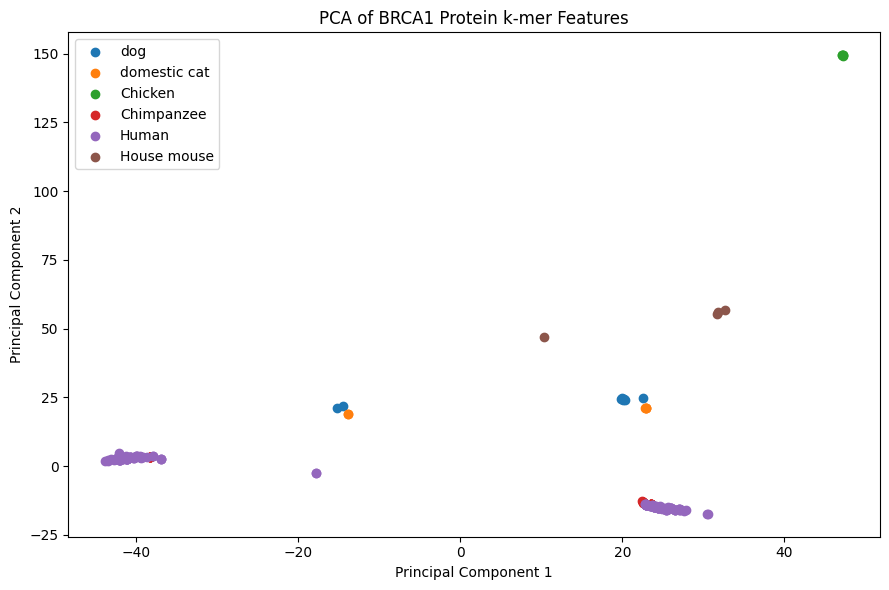

In [85]:
plt.figure(figsize=(9, 6))

for species in protein_unique["species"].unique():

    mask = protein_unique["species"] == species

    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=species
    )

plt.title("PCA of BRCA1 Protein k-mer Features")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.tight_layout()
plt.show()

In [86]:
from sklearn.cluster import KMeans

kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_scaled)

protein_unique["cluster"] = clusters

print(protein_unique["cluster"].value_counts())

cluster
0    100
1     76
2      8
3      5
5      4
4      4
Name: count, dtype: int64


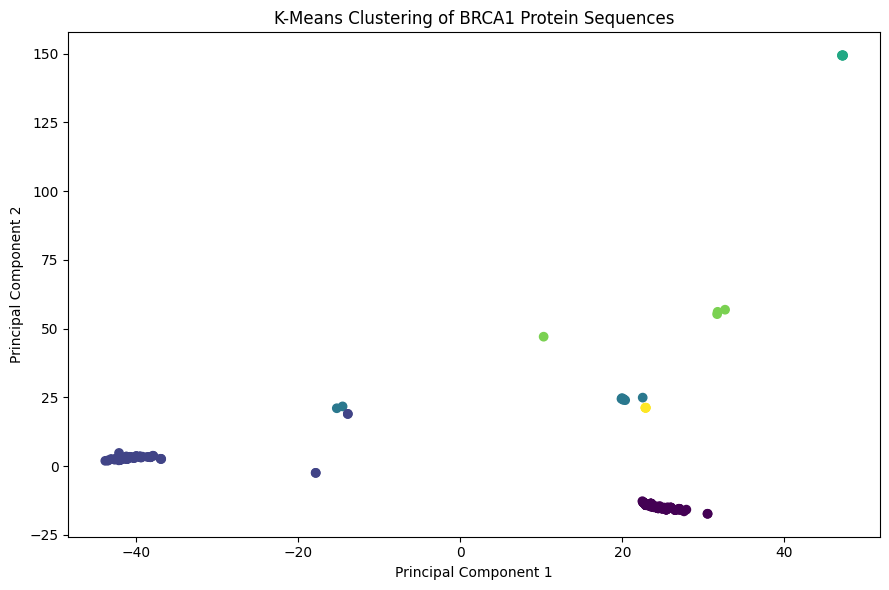

In [87]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=clusters
)

plt.title("K-Means Clustering of BRCA1 Protein Sequences")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

In [88]:
from sklearn.metrics import silhouette_score

score = silhouette_score(
    X_scaled,
    clusters
)

print("Silhouette Score:", score)

Silhouette Score: 0.6636066876002813


# Experimenting Imbalanced Dataset

In [89]:
y = protein_unique["species"]

print(y.value_counts())

species
Human           146
Chimpanzee       28
dog               8
domestic cat      6
Chicken           5
House mouse       4
Name: count, dtype: int64


In [90]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", len(X_train))
print("Testing:", len(X_test))

Training: 157
Testing: 40


In [91]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

model.fit(
    X_train,
    y_train
)

print("Model trained.")

Model trained.


In [92]:
y_pred = model.predict(X_test)

print("Predictions completed.")

Predictions completed.


In [93]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score

accuracy = accuracy_score(y_test, y_pred)

balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_pred
)

macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("Accuracy:", accuracy)
print("Balanced Accuracy:", balanced_accuracy)
print("Macro F1:", macro_f1)

Accuracy: 1.0
Balanced Accuracy: 1.0
Macro F1: 1.0


In [94]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

     Chicken       1.00      1.00      1.00         1
  Chimpanzee       1.00      1.00      1.00         6
 House mouse       1.00      1.00      1.00         1
       Human       1.00      1.00      1.00        30
         dog       1.00      1.00      1.00         1
domestic cat       1.00      1.00      1.00         1

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



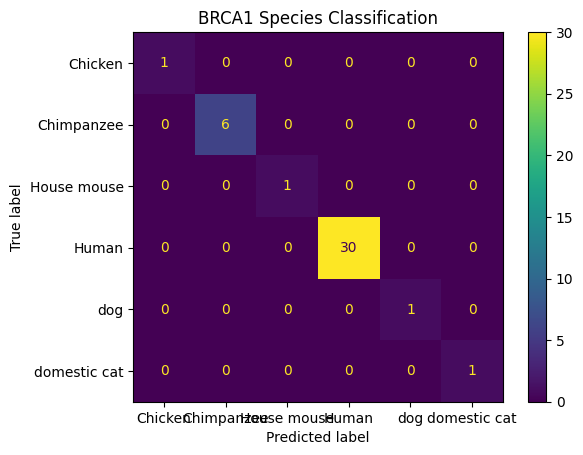

In [95]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

disp.plot()

plt.title("BRCA1 Species Classification")
plt.show()

In [96]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

accuracy_scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="accuracy"
)

balanced_scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="balanced_accuracy"
)

print("Accuracy scores:", accuracy_scores)
print("Mean accuracy:", accuracy_scores.mean())
print("Accuracy SD:", accuracy_scores.std())

print("Balanced accuracy scores:", balanced_scores)
print("Mean balanced accuracy:", balanced_scores.mean())

Accuracy scores: [1. 1. 1. 1.]
Mean accuracy: 1.0
Accuracy SD: 0.0
Balanced accuracy scores: [1. 1. 1. 1.]
Mean balanced accuracy: 1.0


In [97]:
feature_names = vectorizer.get_feature_names_out()

importance = pd.DataFrame({
    "kmer": feature_names,
    "importance": model.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

importance.head(20)

,kmer,importance
1176,HNL,0.010336
2719,RVG,0.008850
309,CSG,0.007831
462,DRA,0.007605
3212,TTN,0.007592
1224,HVG,0.007321
1733,LNA,0.007257
2110,NTA,0.007213
151,ARV,0.007017
736,ESL,0.006951


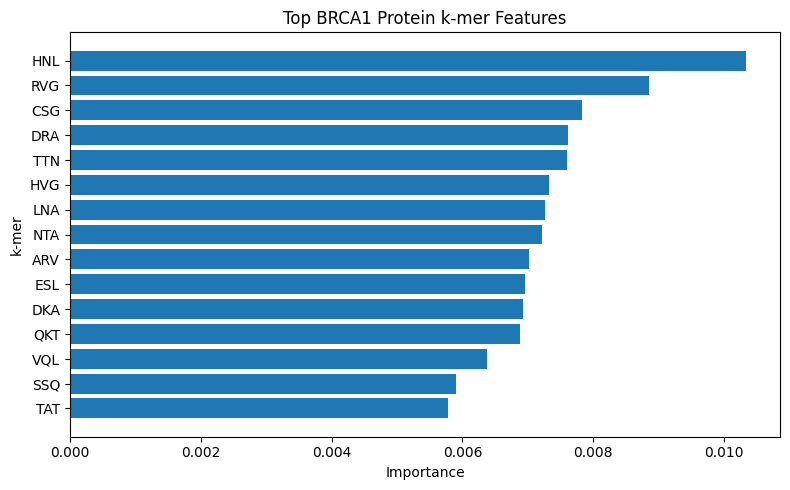

In [98]:
top = importance.head(15)

plt.figure(figsize=(8, 5))

plt.barh(
    top["kmer"],
    top["importance"]
)

plt.xlabel("Importance")
plt.ylabel("k-mer")
plt.title("Top BRCA1 Protein k-mer Features")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [103]:
shared = (
    protein_unique.groupby("sequence")["species"]
    .nunique()
)

shared = shared[shared > 1]

print(
    "Identical sequences shared between species:",
    len(shared)
)

Identical sequences shared between species: 0


In [104]:
shared_sequences = protein_unique[
    protein_unique["sequence"].isin(shared.index)
]

shared_sequences[
    ["species", "id", "sequence"]
]

,species,id,sequence


# Balanced dataset Experiments

In [105]:
human = protein_unique[protein_unique["species"] == "Human"]
other = protein_unique[protein_unique["species"] != "Human"]

human_sample = human.sample(n=28, random_state=42)

balanced_df = pd.concat(
    [human_sample, other],
    ignore_index=True
)

print(balanced_df["species"].value_counts())

species
Human           28
Chimpanzee      28
dog              8
domestic cat     6
Chicken          5
House mouse      4
Name: count, dtype: int64


In [106]:
balanced_kmers = balanced_df["sequence"].apply(
    lambda x: kmer_frequency(x, 3)
)

X_balanced = vectorizer.transform(balanced_kmers)
y_balanced = balanced_df["species"]

print("Dataset shape:", X_balanced.shape)

Dataset shape: (79, 3545)


In [107]:
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_balanced,
    y_balanced,
    test_size=0.20,
    random_state=42,
    stratify=y_balanced
)

balanced_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42
)

balanced_model.fit(X_train_b, y_train_b)

print("Balanced model trained.")

Balanced model trained.


In [108]:
y_pred_b = balanced_model.predict(X_test_b)

print("Accuracy:", accuracy_score(y_test_b, y_pred_b))
print("Balanced Accuracy:", balanced_accuracy_score(y_test_b, y_pred_b))
print("Macro F1:", f1_score(y_test_b, y_pred_b, average="macro"))

Accuracy: 1.0
Balanced Accuracy: 1.0
Macro F1: 1.0


In [109]:
print(classification_report(y_test_b, y_pred_b))

              precision    recall  f1-score   support

     Chicken       1.00      1.00      1.00         1
  Chimpanzee       1.00      1.00      1.00         6
 House mouse       1.00      1.00      1.00         1
       Human       1.00      1.00      1.00         6
         dog       1.00      1.00      1.00         1
domestic cat       1.00      1.00      1.00         1

    accuracy                           1.00        16
   macro avg       1.00      1.00      1.00        16
weighted avg       1.00      1.00      1.00        16



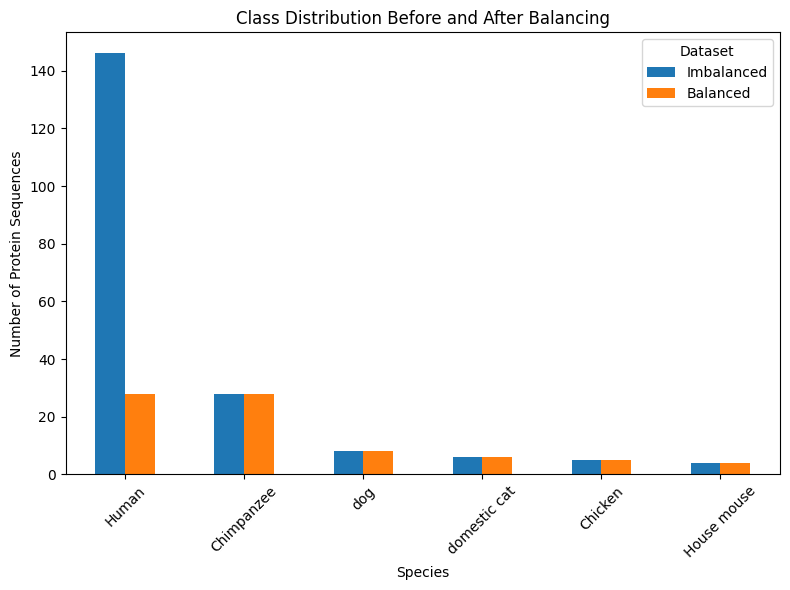

In [111]:
import matplotlib.pyplot as plt
import pandas as pd

imbalanced_counts = protein_unique["species"].value_counts()
balanced_counts = balanced_df["species"].value_counts()

comparison = pd.DataFrame({
    "Imbalanced": imbalanced_counts,
    "Balanced": balanced_counts
}).fillna(0)

comparison.plot(
    kind="bar",
    figsize=(8, 6)
)

plt.title("Class Distribution Before and After Balancing")
plt.xlabel("Species")
plt.ylabel("Number of Protein Sequences")
plt.xticks(rotation=45)
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

IMBALANCED DATASET
Accuracy: 1.0
Balanced Accuracy: 1.0
Macro F1: 1.0

BALANCED DATASET
Accuracy: 1.0
Balanced Accuracy: 1.0
Macro F1: 1.0


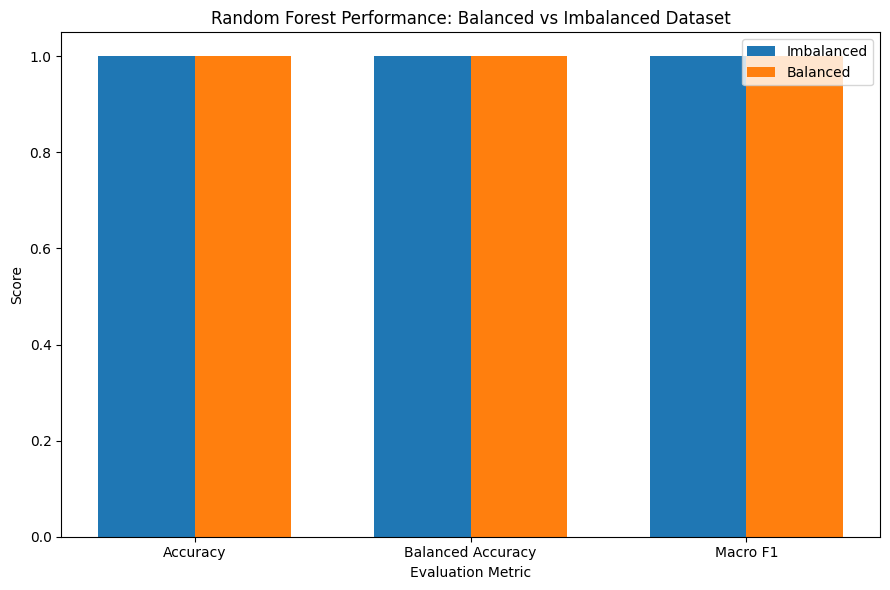

In [120]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
import matplotlib.pyplot as plt
import numpy as np

# Imbalanced dataset metrics
imbalanced_accuracy = accuracy_score(y_test, y_pred)
imbalanced_balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
imbalanced_macro_f1 = f1_score(y_test, y_pred, average="macro")

# Balanced dataset metrics
balanced_accuracy = accuracy_score(y_test_b, y_pred_b)
balanced_balanced_accuracy = balanced_accuracy_score(
    y_test_b,
    y_pred_b
)
balanced_macro_f1 = f1_score(
    y_test_b,
    y_pred_b,
    average="macro"
)

# Print results
print("IMBALANCED DATASET")
print("Accuracy:", imbalanced_accuracy)
print("Balanced Accuracy:", imbalanced_balanced_accuracy)
print("Macro F1:", imbalanced_macro_f1)

print("\nBALANCED DATASET")
print("Accuracy:", balanced_accuracy)
print("Balanced Accuracy:", balanced_balanced_accuracy)
print("Macro F1:", balanced_macro_f1)


# Comparison visualisation
metrics = [
    "Accuracy",
    "Balanced Accuracy",
    "Macro F1"
]

imbalanced_scores = [
    imbalanced_accuracy,
    imbalanced_balanced_accuracy,
    imbalanced_macro_f1
]

balanced_scores = [
    balanced_accuracy,
    balanced_balanced_accuracy,
    balanced_macro_f1
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 6))

plt.bar(
    x - width/2,
    imbalanced_scores,
    width,
    label="Imbalanced"
)

plt.bar(
    x + width/2,
    balanced_scores,
    width,
    label="Balanced"
)

plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.title("Random Forest Performance: Balanced vs Imbalanced Dataset")
plt.xticks(x, metrics)
plt.ylim(0, 1.05)
plt.legend()

plt.tight_layout()
plt.show()

In [121]:
df.to_csv(
    "/content/BRCA1_processed_dataset.csv",
    index=False
)

print("Processed dataset saved.")

Processed dataset saved.


In [122]:
protein_unique.to_csv(
    "/content/BRCA1_unique_proteins.csv",
    index=False
)

print("Unique protein dataset saved.")

Unique protein dataset saved.
